# Possession pipeline — summary and run

This notebook is the executable overview. The detailed reasoning is kept in the numbered guides next to it.

## What we do

1. Load and audit the supplied ATD, Smart Tagging, and metadata tables.
2. Apply the published graded-frame mask; output `X` outside the two graded intervals.
3. Build pitch distances, margins, zones, pressure, movement, reachability, and reception features.
4. Identify dead-ball context, comfortable-control anchors, flight, contest, occlusion, and reception scenarios.
5. Resolve bounded trajectories using previous anchors and later controlled reception evidence.
6. Protect strong `D` and `X` evidence, write H/A/D/X labels, and evaluate Macro-F1 and Spell-F1.

This is an offline trajectory-classification pipeline. A scenario may look forward to the later receiver, but the current H/A label is preserved until controlled reception evidence confirms a switch. The rule hierarchy is documented in `3b_RULE_BOOK.md`; Viterbi, HMM, and HSMM are registered alternative decoders rather than methods blindly stacked together.

## Modular implementation

The notebook calls a thin canonical runner. The runner performs three stages:

1. build the complete feature/evidence table;
2. detect scenario evidence;
3. pass that evidence to one explicitly selected model.

The model selector is deliberately separate from the feature and scenario functions. This notebook runs one selected model and writes its frame-aligned submission; notebook 08 owns the multi-model leaderboard.

In [1]:
# Setup: choose one model and keep paths in one place.
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "possession").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from possession.baseline_pipeline import ClosestTeamRuleModel
from possession.pipeline import run_decision_pipeline, select_model

MODEL_NAME = "evidence_bounded_deadball"
MODEL_SPEC = select_model(MODEL_NAME)
RESULTS = ROOT / "evaluation" / "results"
OUTPUT = RESULTS / f"selected_{MODEL_NAME}.csv"
print("project root:", ROOT)
print("selected model:", MODEL_SPEC)
print("output:", OUTPUT)


project root: /Users/luke/Desktop/barca-hack-repo-staging
selected model: PipelineSpec(name='evidence_bounded_deadball', anchor_source='selected_anchor_team', use_smart_set_piece=True, use_dead_ball_boundary=True, use_literal_out_of_bounds=False, transition_rule='aligned_reception', use_physics_veto=True, decoder='none', protect_dead_ball=False, protect_outside_graded=True, minimum_control_anchor_confidence=0.65, use_genuine_control_anchor=False)
output: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/selected_evidence_bounded_deadball.csv


## Run one selected model

The public runner now makes the composition explicit: features → scenarios → selected model.

In [2]:
# Build evidence, detect scenarios, apply the selected model, and store one result.
data_model = ClosestTeamRuleModel()
features, labels = run_decision_pipeline(
    model=data_model,
    model_name=MODEL_NAME,
)
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
data_model.write_submission(OUTPUT, labels)
print("frames:", len(features))
print("labels:", dict(zip(*__import__("numpy").unique(labels, return_counts=True))))
print("stored:", OUTPUT)
confidence_columns = [
    column for column in [
        "scenario_confidence", "scenario_margin",
        "selected_anchor_confidence", "controlled_reception_signal_score",
    ] if column in features.columns
]
print("confidence signals:", confidence_columns)
if confidence_columns:
    display(features[["frame", *confidence_columns]].dropna(how="all").head(10))


/Users/luke/Desktop/barca-hack-repo-staging/possession/temporal_rules.py:823: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["goal_kick_opponents_clear"] = goal_kick & (inside_count == 0) & (visible_count >= 5)
/Users/luke/Desktop/barca-hack-repo-staging/possession/temporal_rules.py:824: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["goal_kick_settled_candidate"] = goal_kick & out["goal_kick_opponents_clear"] & low_motion & speed.le(1.0).fillna(True)
/Users/luke/Desktop/barca-hack-repo-staging/possession/temporal_rules.py

frames: 199319
labels: {np.str_('A'): np.int64(35296), np.str_('D'): np.int64(68402), np.str_('H'): np.int64(55159), np.str_('X'): np.int64(40462)}
stored: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/results/selected_evidence_bounded_deadball.csv
confidence signals: ['scenario_confidence', 'scenario_margin', 'selected_anchor_confidence', 'controlled_reception_signal_score']


,frame,scenario_confidence,scenario_margin,selected_anchor_confidence,controlled_reception_signal_score
0,0,1.0,0.7,0.0,NaN
1,1,1.0,0.7,0.0,NaN
2,2,1.0,0.7,0.0,NaN
3,3,1.0,0.7,0.0,NaN
4,4,1.0,0.7,0.0,NaN
5,5,1.0,0.7,0.0,NaN
6,6,1.0,0.7,0.0,NaN
7,7,1.0,0.7,0.0,NaN
8,8,1.0,0.7,0.0,NaN
9,9,1.0,0.7,0.0,NaN


## Inspect one internal ball gap

This diagnostic plot is separate from submission labelling. Solid blue segments are observed ball coordinates; the orange dotted bridge is the missing interval; the purple dashed path is nearest-player geometry; red and green dots are player positions at one reference frame.

Smart Tagging is shown as a context clue only. It can cover preparation, flight, and reception together, so we inspect it selectively rather than copying its team label to every frame. ATD coordinates are normalised in the data and converted here to the supplied pitch in metres: x=0..105.3 and y=0..68.


/Users/luke/Desktop/barca-hack-repo-staging/possession/temporal_rules.py:823: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["goal_kick_opponents_clear"] = goal_kick & (inside_count == 0) & (visible_count >= 5)
/Users/luke/Desktop/barca-hack-repo-staging/possession/temporal_rules.py:824: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["goal_kick_settled_candidate"] = goal_kick & out["goal_kick_opponents_clear"] & low_motion & speed.le(1.0).fillna(True)
/Users/luke/Desktop/barca-hack-repo-staging/possession/temporal_rules.py

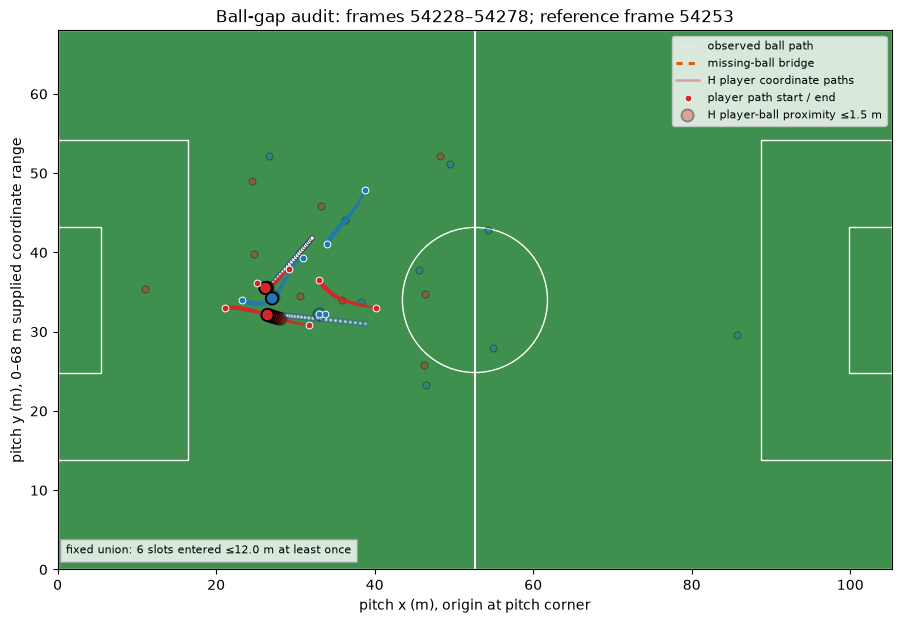

In [3]:
# Diagnostic only: visualise observed, missing, and nearest-player geometry.
from possession.baseline_pipeline import ClosestTeamRuleModel, slot_team_map
from possession.pipeline import build_evidence_table as build_engineered_features
from possession.calculations.plotting import plot_trajectory_window, select_representative_ball_gap
from games import asset_paths
from possession.temporal_rules import load_rules
import matplotlib.pyplot as plt
import numpy as np

rules = load_rules()
model = ClosestTeamRuleModel()
plot_features = build_engineered_features(model=model, rules=rules)
gap = select_representative_ball_gap(plot_features)
if gap is None:
    print('No internal ball-coordinate gap was found.')
else:
    gap_start, gap_end = gap
    team_by_slot = slot_team_map(asset_paths(model.game, model.data_dir, source='tactical')['atd_meta'])
    fig, ax = plot_trajectory_window(plot_features, max(0, gap_start - 25), gap_end + 25, team_by_slot=team_by_slot, reference_frame=(gap_start + gap_end) // 2)
    plt.show()


## Public ground-truth comparison

This is a sanity check against the five-minute public slice shipped with the challenge. It scores the labels produced above over the complete public slice, not just one plotted example. The private full-match ground truth is not available locally, so it is not claimed here.

The scorer ignores ground-truth `X` rows and reports the same frame-level, spell-level, dead-ball, and transition views used by the challenge evaluator.

In [4]:
import sys
import pandas as pd

sys.path.insert(0, str(ROOT / 'evaluation'))
import possession_metrics as pm

public_gt_path = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
if not public_gt_path.exists():
    raise FileNotFoundError(f'Public ground truth not found: {public_gt_path}')

gt_table = pm.read_label_csv(public_gt_path)
gt_codes = pm.label_codes(gt_table)
pred_table = pd.DataFrame({'frame': features['frame'].astype(int), 'label': labels})
pred_codes = pm.label_codes(pred_table)
scores = pm.evaluate(gt_codes, pred_codes, bootstrap_n=0)

comparison = pd.Series({
    'model': MODEL_NAME,
    'ground_truth': public_gt_path.name,
    'frames_compared': scores['n_frames'],
    'graded_frames': scores['n_graded'],
    'macro_f1': scores['macro_f1'],
    'spell_f1_mean': scores['spell_f1_mean'],
    'H_f1': scores['per_class']['H']['f1'],
    'A_f1': scores['per_class']['A']['f1'],
    'D_f1': scores['per_class']['D']['f1'],
    'D_precision': scores['per_class']['D']['precision'],
    'D_recall': scores['per_class']['D']['recall'],
    'transition_f1_at_12_frames': scores['transitions'][12]['f1'],
    'transition_f1_at_25_frames': scores['transitions'][25]['f1'],
}).to_frame('value')
display(comparison)

# A compact audit table makes the score actionable: inspect the first public disagreements.
audit = pd.DataFrame({
    'frame': features['frame'].astype(int),
    'ground_truth': gt_table['label'].astype(str).str.upper(),
    'prediction': pred_table['label'].astype(str).str.upper(),
})
audit['match'] = audit['ground_truth'].eq(audit['prediction'])
display(audit.loc[(audit['ground_truth'] != 'X') & (~audit['match'])].head(25))

,value
model,evidence_bounded_deadball
ground_truth,BAR-ATH_possession_gt_public.csv
frames_compared,199319
graded_frames,7500
macro_f1,0.78312
spell_f1_mean,0.5
H_f1,0.875125
A_f1,0.795635
D_f1,0.678599
D_precision,0.792007


,frame,ground_truth,prediction,match
11351,11351,H,A,False
11352,11352,H,A,False
11353,11353,H,A,False
11354,11354,H,A,False
11355,11355,H,A,False
11356,11356,H,A,False
11357,11357,H,A,False
11358,11358,H,A,False
11359,11359,H,A,False
11360,11360,H,A,False


## Public timeline comparison

The score is also inspected as a time series. Each panel is one contiguous public graded interval; the strip is the supplied ground truth and the dots/scenarios are the model evidence used around it. This makes early or late switches visible instead of hiding them inside F1.

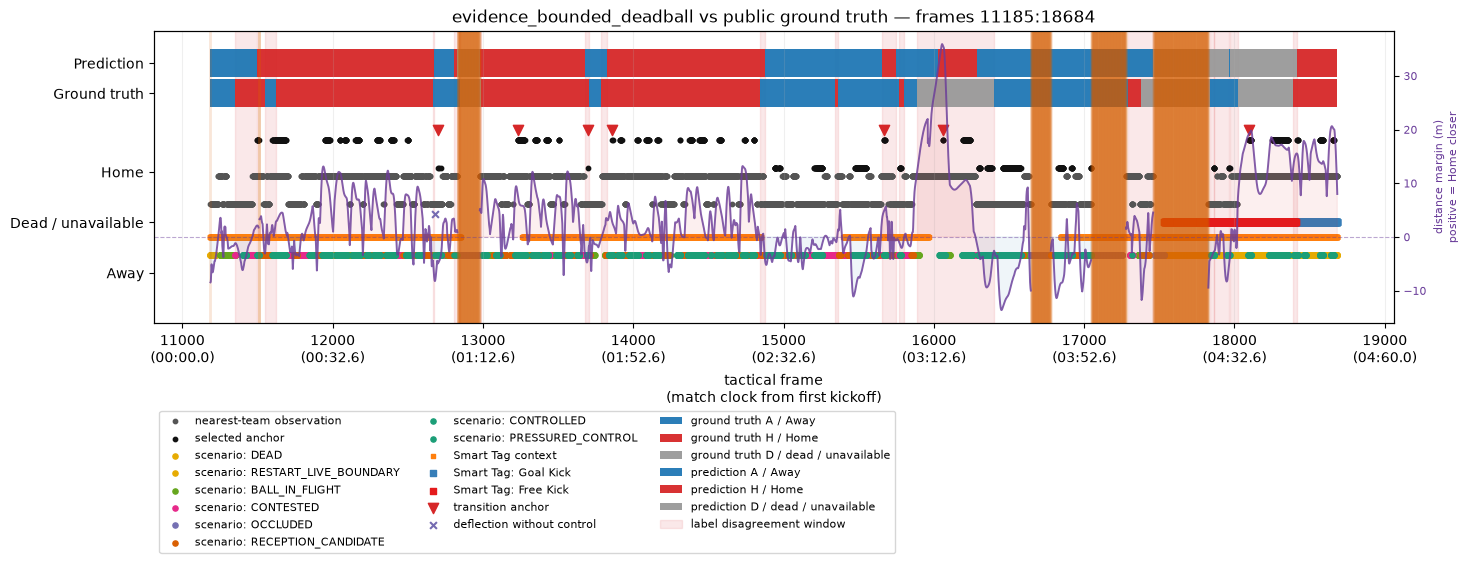

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from possession.calculations.plotting import plot_timeline_window

gt_by_frame = gt_table.set_index('frame')['label'].astype(str).str.upper()
pred_by_frame = pred_table.set_index('frame')['label'].astype(str).str.upper()
public_runs = pm.valid_runs(gt_codes)
fig, axes = plt.subplots(len(public_runs), 1, figsize=(16, 3.8 * len(public_runs)), squeeze=False)
for axis, (run_start, run_stop) in zip(axes[:, 0], public_runs):
    plot_timeline_window(features, run_start, run_stop - 1, ground_truth=gt_by_frame, predicted_labels=pred_by_frame, ax=axis)
    axis.set_title(f'{MODEL_NAME} vs public ground truth — frames {run_start}:{run_stop - 1}')
plt.show()

## Focused disagreement window

The following view selects the longest contiguous public disagreement window. It is a diagnostic window for inspecting why the model differs from the supplied label; it is not used to fit or tune the model.

,start_frame,end_frame,duration_s
0,15889,16399,20.44
1,17293,17455,6.52
2,11351,11497,5.88
3,17867,17963,3.88
4,15656,15746,3.64
5,11553,11623,2.84
6,17968,18026,2.36
7,12805,12850,1.84
8,13785,13825,1.64
9,15766,15798,1.32


wrong graded frames: 1404


,frame,ground_truth,prediction,match,match_clock_s,scenario_context,closest_team,selected_anchor_team,selected_anchor_confidence,scenario_confidence,scenario_margin,controlled_reception_signal_score
0,11351,H,A,False,6.64,BALL_IN_FLIGHT,A,NaN,0.0,1.000000,0.223762,0.080000
1,11352,H,A,False,6.68,BALL_IN_FLIGHT,A,NaN,0.0,1.000000,0.222523,0.040000
2,11353,H,A,False,6.72,BALL_IN_FLIGHT,A,NaN,0.0,1.000000,0.222035,0.200000
3,11354,H,A,False,6.76,BALL_IN_FLIGHT,A,NaN,0.0,1.000000,0.222234,0.200000
4,11355,H,A,False,6.80,UNKNOWN,A,NaN,0.0,0.431864,0.113687,0.200000
5,11356,H,A,False,6.84,UNKNOWN,A,NaN,0.0,0.411768,0.092374,0.200000
6,11357,H,A,False,6.88,UNKNOWN,A,NaN,0.0,0.395447,0.076513,0.200000
7,11358,H,A,False,6.92,UNKNOWN,A,NaN,0.0,0.382928,0.068107,0.200000
8,11359,H,A,False,6.96,UNKNOWN,A,NaN,0.0,0.370358,0.063163,0.200000
9,11360,H,A,False,7.00,UNKNOWN,A,NaN,0.0,0.358311,0.063633,0.200000


full frame-level error audit: /Users/luke/Desktop/barca-hack-repo-staging/evaluation/reports/evidence_bounded_deadball_public_frame_errors.csv
Smart Tag context in longest disagreement window:


,frames
smart_context,
PLAYERS IN THE BOX,77


foul-specific Smart Tag present: False


,error_type,count
0,missed_deadball,597
1,wrong_team,578
2,overheld_deadball,229


,ground_truth_frame,predicted_frame,ground_truth_from,ground_truth_to,predicted_from,predicted_to,frame_delta,error_type,match_clock_s
0,11351.0,NaN,A,H,NaN,NaN,NaN,missed_transition,NaN
1,11553.0,NaN,H,A,NaN,NaN,NaN,missed_transition,NaN
2,11624.0,NaN,A,H,NaN,NaN,NaN,missed_transition,NaN
3,12665.0,12674.0,H,A,H,A,9.0,late_transition,59.20
4,12851.0,12831.0,A,D,H,D,-20.0,early_transition,66.64
...,...,...,...,...,...,...,...,...,...
518,NaN,188432.0,NaN,NaN,A,D,NaN,spurious_transition,NaN
519,NaN,188617.0,NaN,NaN,D,A,NaN,spurious_transition,NaN
520,NaN,189343.0,NaN,NaN,A,D,NaN,spurious_transition,NaN
521,NaN,189920.0,NaN,NaN,D,A,NaN,spurious_transition,NaN


rendering every disagreement window


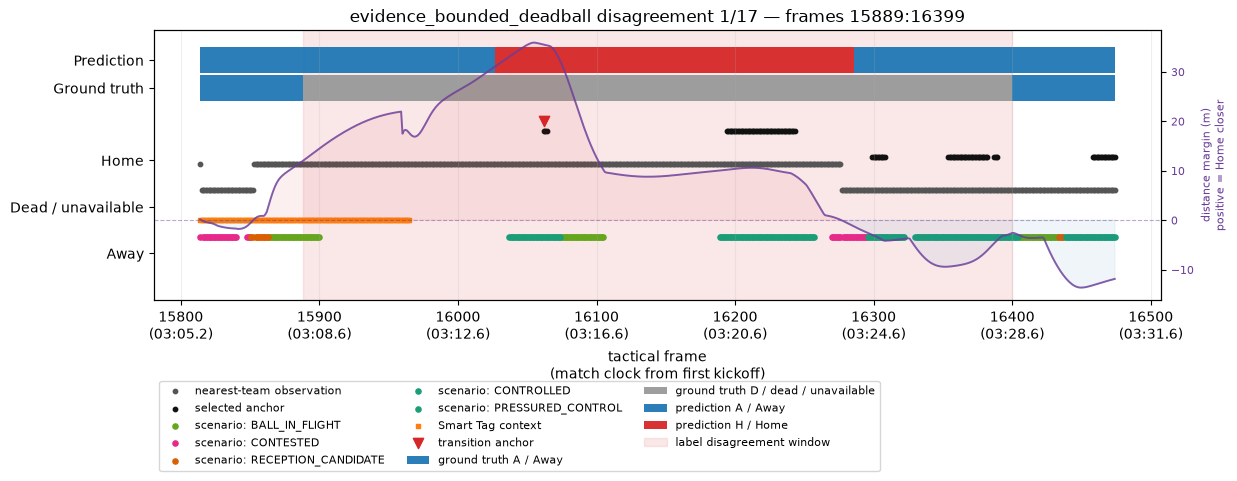

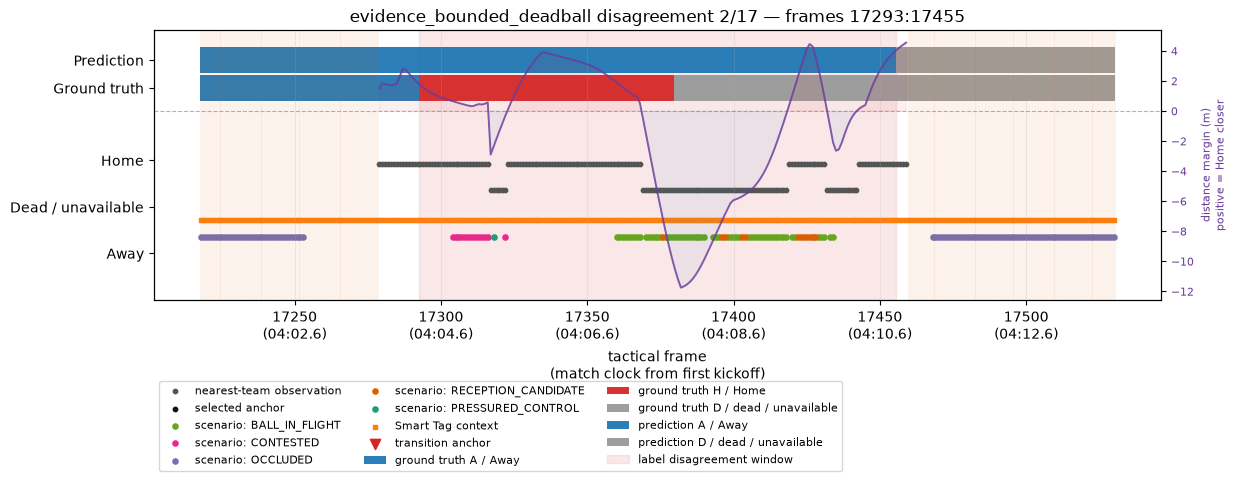

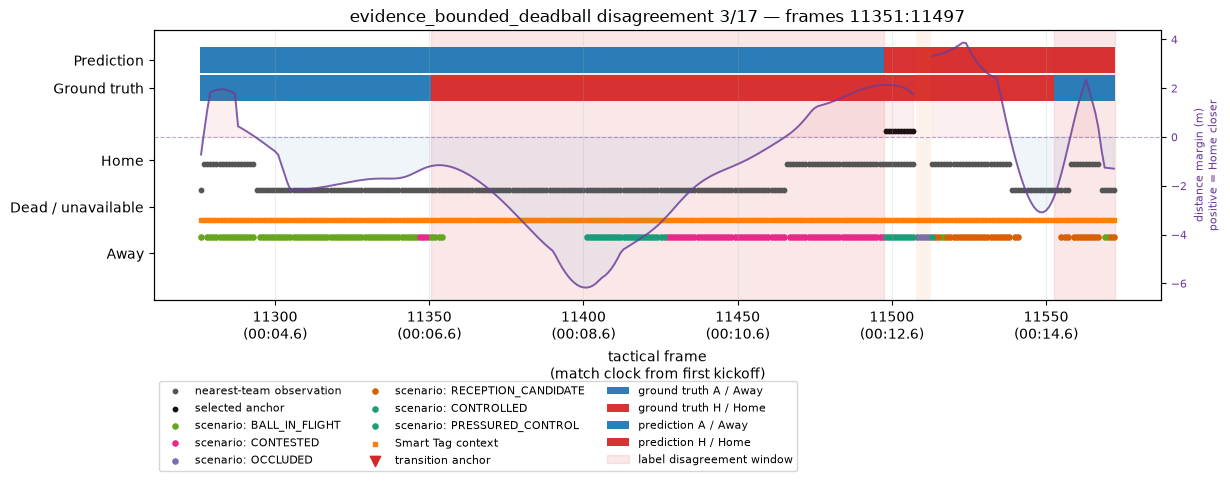

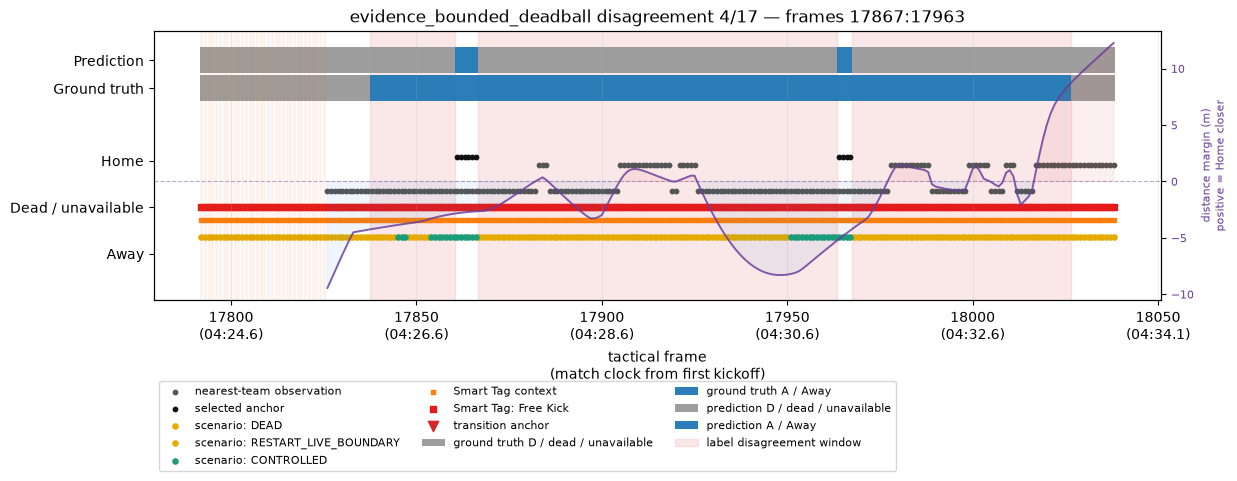

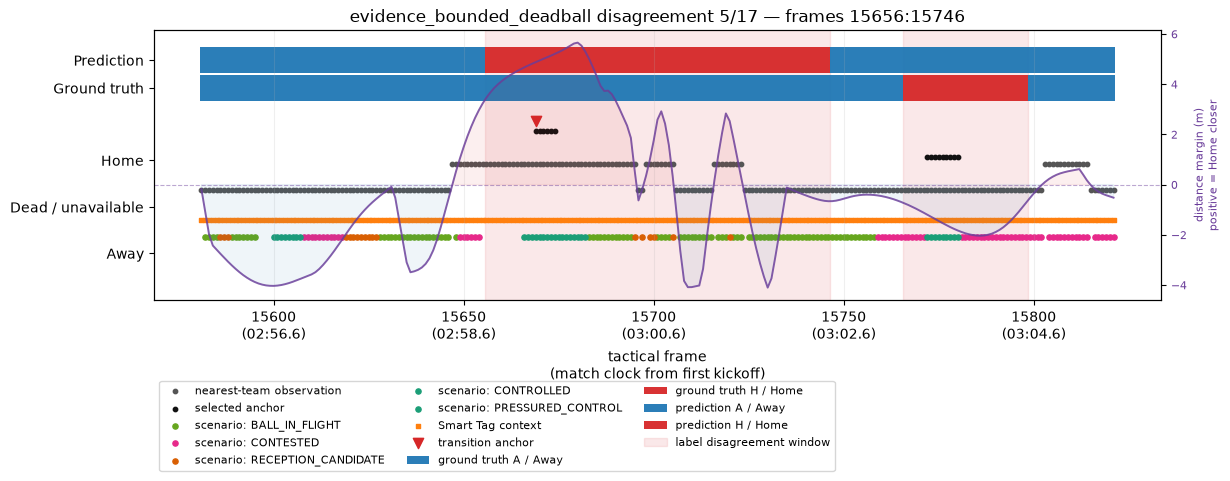

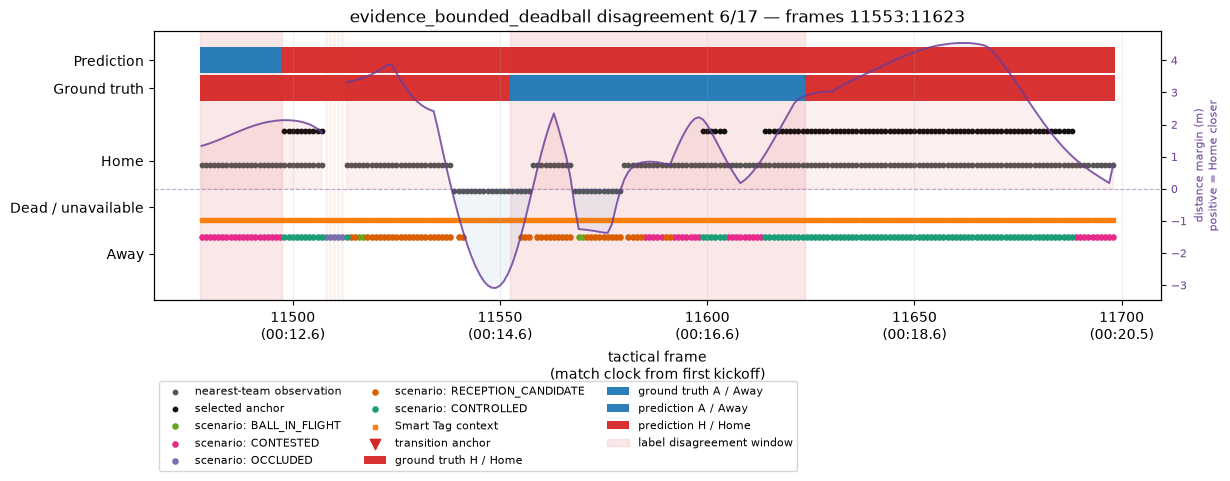

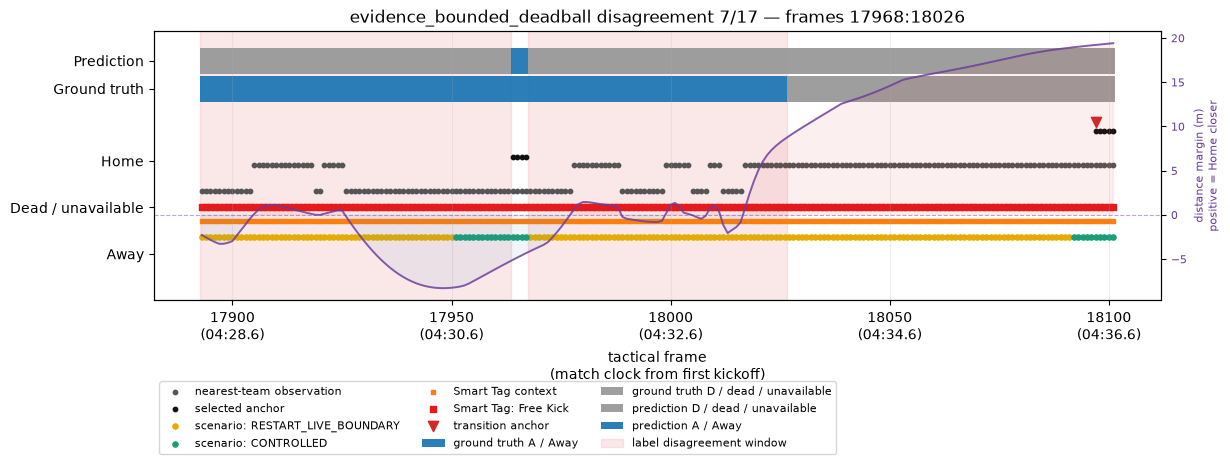

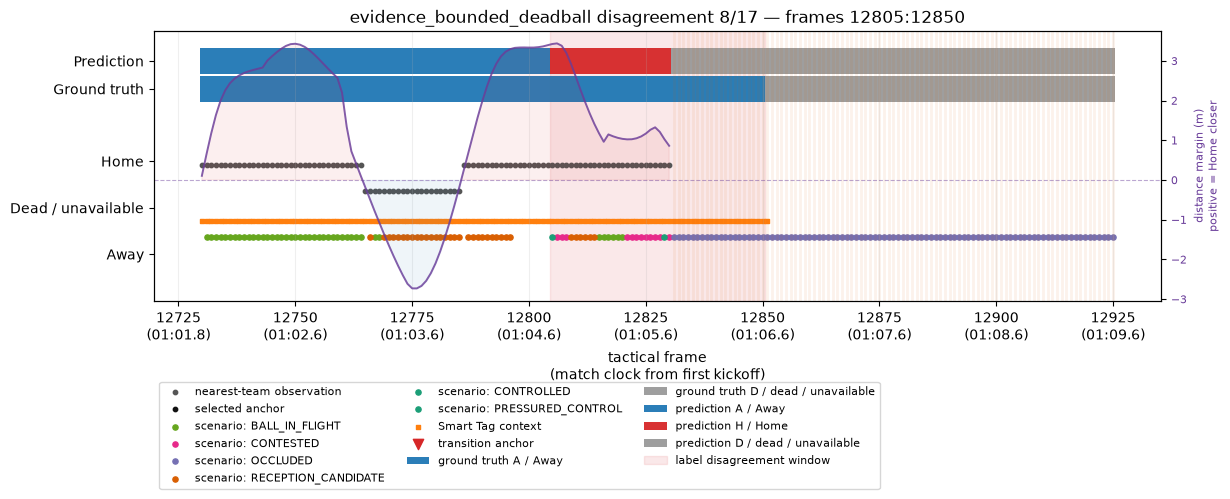

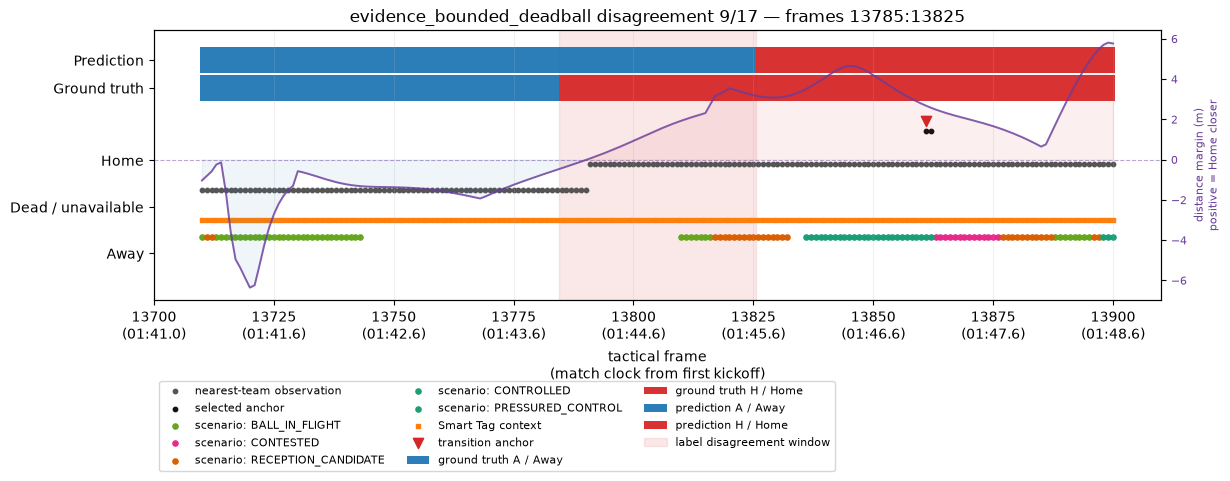

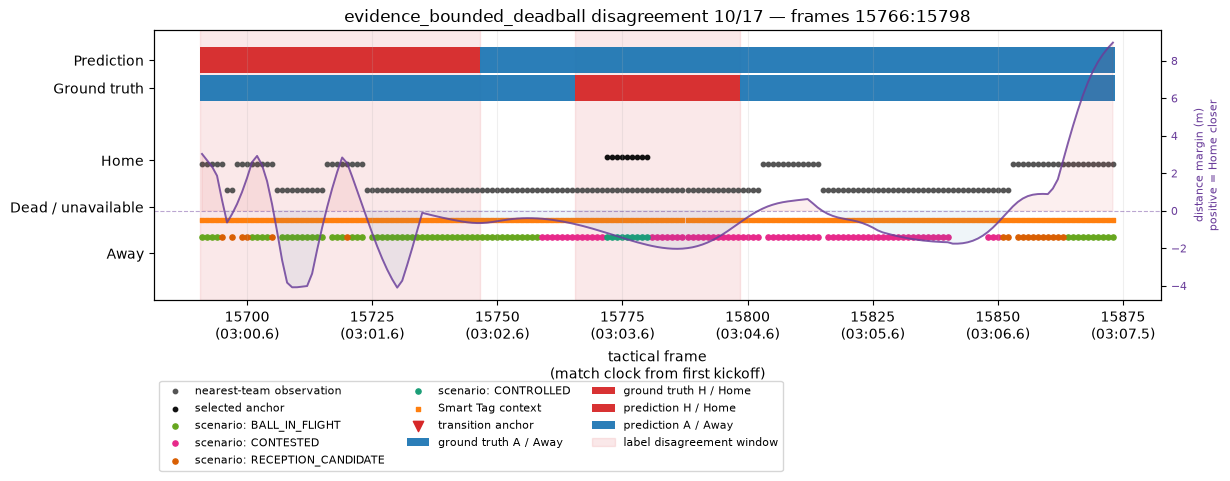

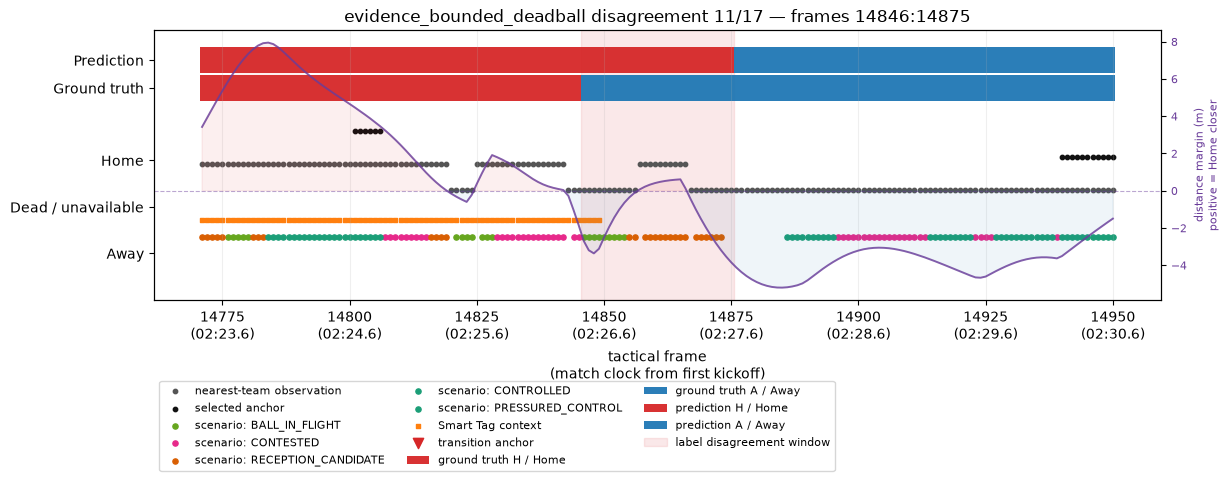

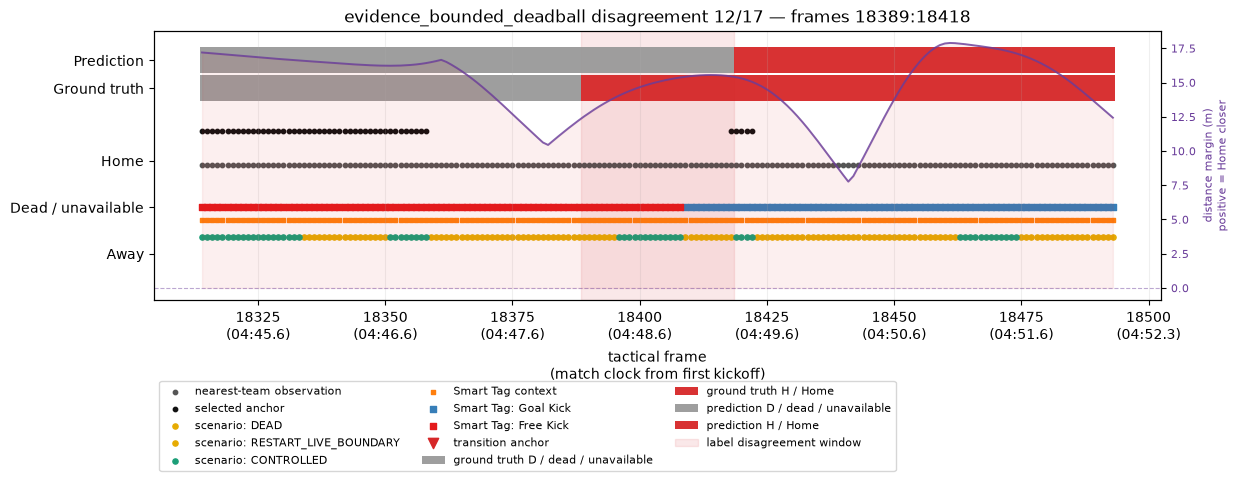

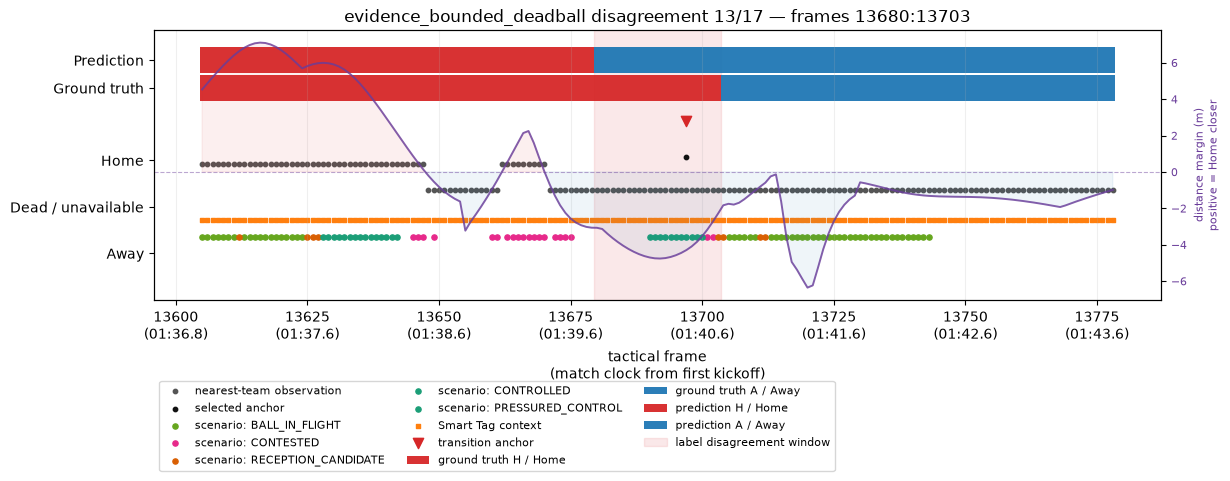

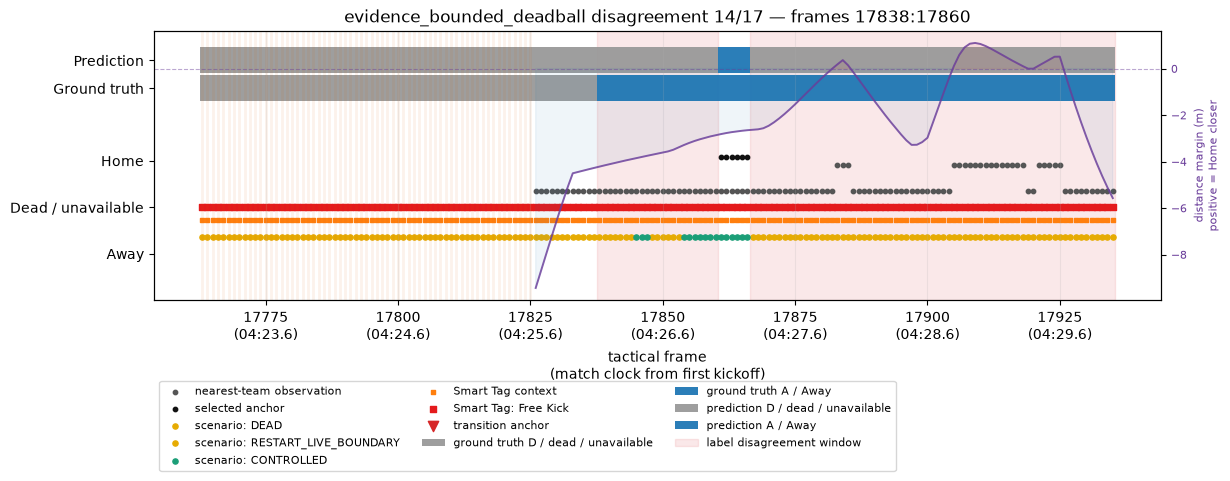

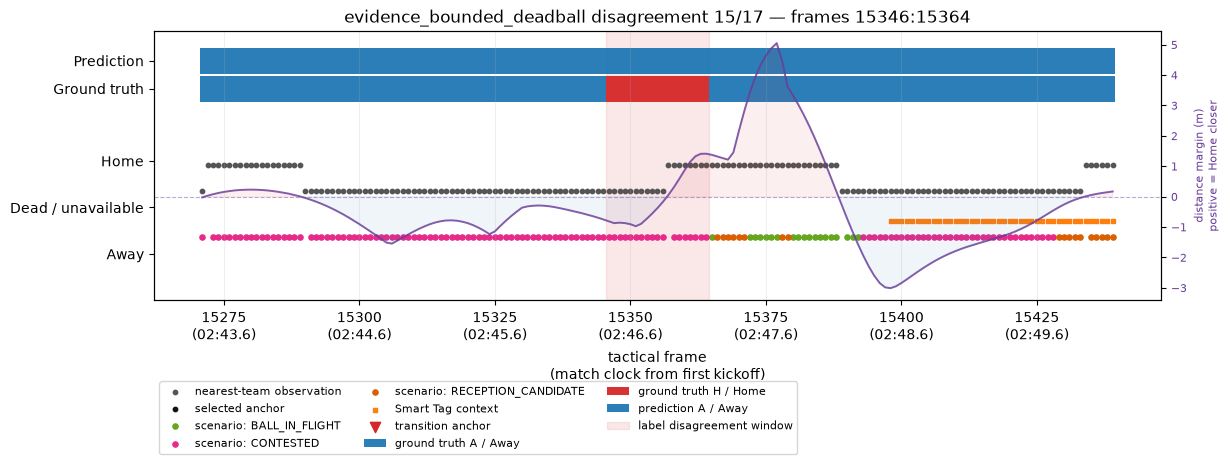

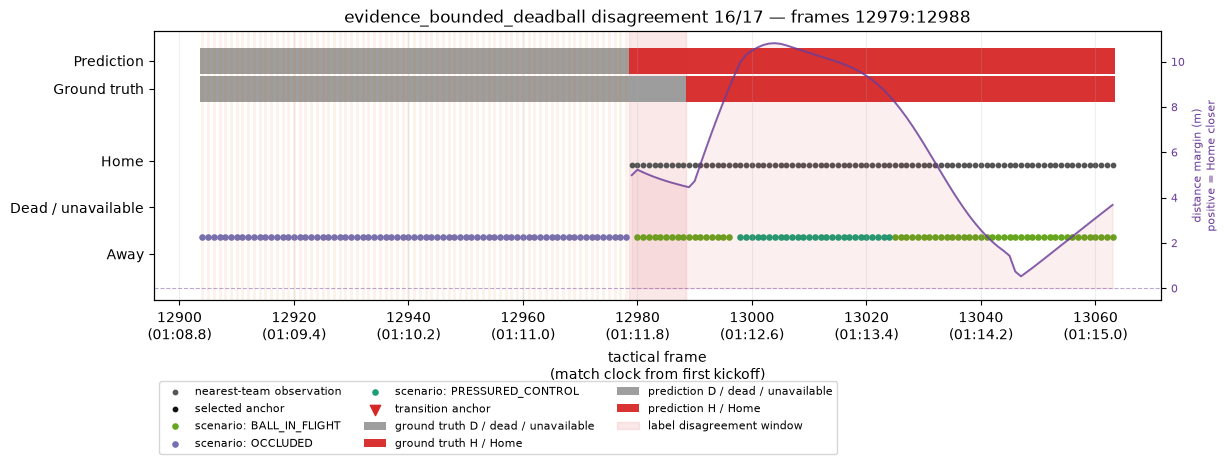

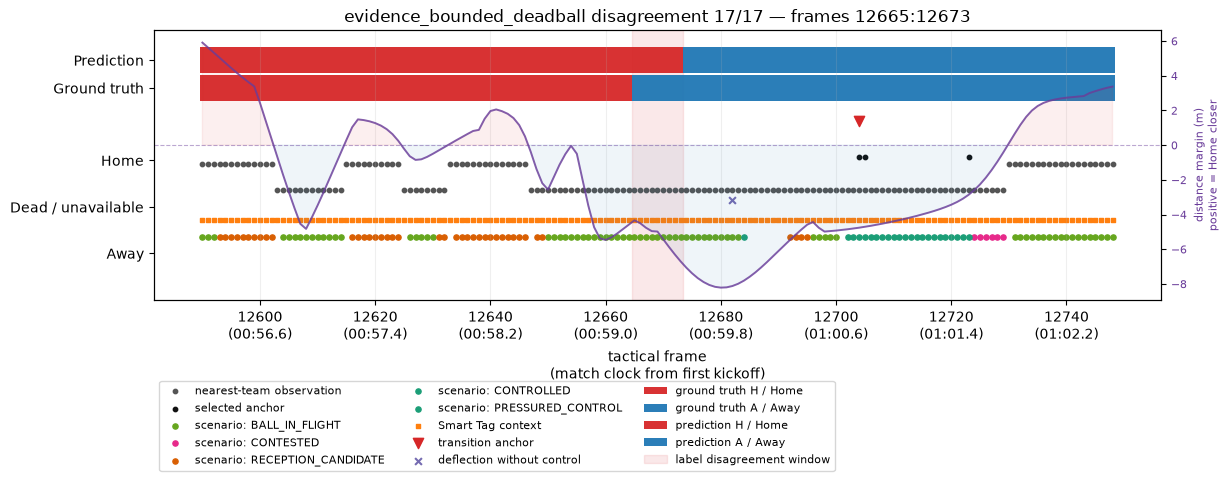

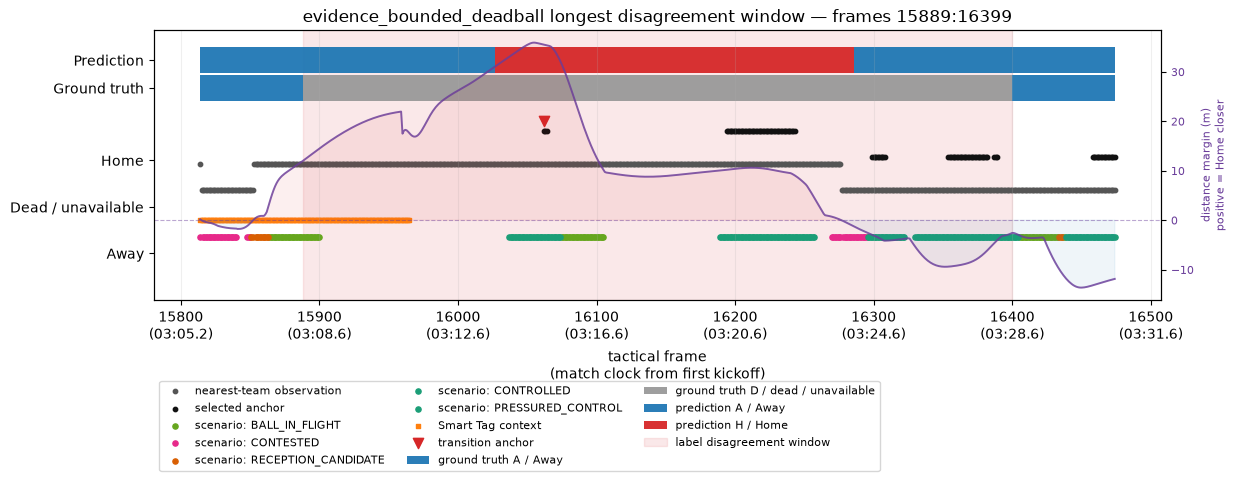

In [6]:
graded_mismatch = (gt_by_frame != 'X') & gt_by_frame.notna() & pred_by_frame.notna() & gt_by_frame.ne(pred_by_frame)
mismatch_frames = graded_mismatch[graded_mismatch].index.to_numpy(dtype=int)
if len(mismatch_frames) == 0:
    print('No public label disagreements in the selected run.')
else:
    groups = np.split(mismatch_frames, np.where(np.diff(mismatch_frames) > 1)[0] + 1)
    mismatch_windows = sorted(((int(group[0]), int(group[-1])) for group in groups), key=lambda pair: pair[1] - pair[0], reverse=True)
    mismatch_start, mismatch_end = mismatch_windows[0]
    context = 75
    left = max(int(features['frame'].min()), mismatch_start - context)
    right = min(int(features['frame'].max()), mismatch_end + context)
    mismatch_table = pd.DataFrame(mismatch_windows, columns=['start_frame', 'end_frame'])
    mismatch_table['duration_s'] = (mismatch_table['end_frame'] - mismatch_table['start_frame'] + 1) / 25.0
    display(mismatch_table.head(10))
    audit_columns = ['frame', 'match_clock_s', 'scenario_context', 'closest_team', 'selected_anchor_team', 'selected_anchor_confidence', 'scenario_confidence', 'scenario_margin', 'controlled_reception_signal_score']
    audit_features = features[[column for column in audit_columns if column in features.columns]].copy()
    wrong_frames = audit.loc[(audit['ground_truth'] != 'X') & (~audit['match'])].merge(audit_features, on='frame', how='left')
    print(f'wrong graded frames: {len(wrong_frames)}')
    display(wrong_frames.head(50))
    error_output = ROOT / 'evaluation' / 'reports' / f'{MODEL_NAME}_public_frame_errors.csv'
    error_output.parent.mkdir(parents=True, exist_ok=True)
    wrong_frames.to_csv(error_output, index=False)
    print('full frame-level error audit:', error_output)
    smart_window = features.loc[features['frame'].between(mismatch_start, mismatch_end), 'smart_context'].dropna() if 'smart_context' in features.columns else pd.Series(dtype='object')
    print('Smart Tag context in longest disagreement window:')
    display(smart_window.value_counts().rename_axis('smart_context').to_frame('frames'))
    print('foul-specific Smart Tag present:', bool(smart_window.astype(str).str.contains('foul', case=False).any()))
    from possession.evaluation_audit import classify_prediction_errors
    diagnostics = classify_prediction_errors(features, gt_by_frame, pred_by_frame)
    display(diagnostics['summary'])
    display(diagnostics['transition_errors'])
    print('rendering every disagreement window')
    for window_number, (window_start, window_end) in enumerate(mismatch_windows, start=1):
        left = max(int(features['frame'].min()), window_start - context)
        right = min(int(features['frame'].max()), window_end + context)
        fig, ax = plot_timeline_window(features, left, right, ground_truth=gt_by_frame, predicted_labels=pred_by_frame)
        ax.set_title(f'{MODEL_NAME} disagreement {window_number}/{len(mismatch_windows)} — frames {window_start}:{window_end}')
        plt.show()
    left = max(int(features['frame'].min()), mismatch_start - context)
    right = min(int(features['frame'].max()), mismatch_end + context)
    fig, ax = plot_timeline_window(features, left, right, ground_truth=gt_by_frame, predicted_labels=pred_by_frame)
    ax.set_title(f'{MODEL_NAME} longest disagreement window — frames {mismatch_start}:{mismatch_end}')
    plt.show()

## Read the reasoning around the run

- [01 — EDA](./01_eda.ipynb)
- [02 — Feature engineering](./02_feature_engineering.ipynb)
- [03 — Scenario engineering](./03_scenario_engineering.ipynb)
- [05 — Anchors](./05_anchors_rulebook.ipynb)
- [06 — Transition markers](./06_transition_markers.ipynb)
- [07 — Viterbi model](./07_viterbi_model.ipynb)
- [09 — Experimental results](./09_experimental_results.ipynb)